# Frozen ResNet18 versus Duong DenseNet — prespecified paired comparison
DSA5206 Type-2 alternative model experiment. Existing reproduction and assessment artifacts are read-only. No empirical superiority claim is made before real-data execution.

Primary alternative: frozen ImageNet ResNet18 → 512 features → fold-local StandardScaler → Ridge. Primary baseline: chest-X-ray pretrained DenseNet → pre-sigmoid Lung Opacity logit → OLS. This compares complete pipelines, **not architecture alone**: pretrained populations, preprocessing, dimensionality and regularization differ.

Fixed outer seeds 0–49; scatter seed 0. Inner model selection uses training patients only. No end-to-end fine-tuning, seed search or test-guided hyperparameter changes. Optional PCA is disabled initially.


In [1]:
!git clone --branch resnet18-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

Cloning into '/content/nus_DSA5206_GROUPPROJECT'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 60 (delta 16), reused 22 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 8.01 MiB | 14.24 MiB/s, done.
Resolving deltas: 100% (16/16), done.


In [1]:
# Colab: run once, restart runtime if requested, then continue below.
%pip install torch==2.5.1 torchvision==0.20.1 torchxrayvision==1.4.0 numpy==1.26.4 pandas==2.2.3 scipy==1.14.1 scikit-learn==1.5.2 scikit-image==0.24.0 matplotlib==3.9.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.5/906.5 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 57.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/36

In [1]:
import torch
import torchvision
import torchxrayvision as xrv

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Environment OK")

PyTorch: 2.5.1+cu124
Torchvision: 0.20.1+cu124
Environment OK


In [2]:
# Optional Drive mount:
from google.colab import drive
drive.mount('/content/drive')
import os,sys,json,platform,importlib.metadata,shutil
from pathlib import Path
from time import perf_counter
from urllib.parse import urlparse
REPO_DIR=Path(os.environ.get('DUONG_REPO_DIR','/content/nus_DSA5206_GROUPPROJECT')).resolve()
DATA_DIR=Path(os.environ.get('DUONG_DATA_DIR','/content/drive/MyDrive/duong-data')).resolve()
IMAGE_DIR=Path(os.environ.get('DUONG_IMAGE_DIR',str(DATA_DIR/'images')))
METADATA_CSV=Path(os.environ.get('DUONG_METADATA_CSV',str(DATA_DIR/'metadata_2020.csv')))
SCORES_CSV=Path(os.environ.get('DUONG_SCORES_CSV',str(DATA_DIR/'covid-severity-scores.csv')))
ASSESSMENT_DIR=Path(os.environ.get('DUONG_CRITICAL_RESULTS_DIR','/content/duong-critical-assessment-results'))
REPRO_DIR=Path(os.environ.get('DUONG_REPRO_RESULTS_DIR','/content/duong-improved-results'))
OUTPUT_DIR=Path('/content/duong-resnet18-results/').resolve()
assert OUTPUT_DIR != REPO_DIR and REPO_DIR not in OUTPUT_DIR.parents
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
os.chdir(OUTPUT_DIR);sys.path.insert(0,str(REPO_DIR))
INCLUDE_PCA=False  # optional secondary experiment, set before seeing test results
assert IMAGE_DIR.is_dir() and METADATA_CSV.is_file() and SCORES_CSV.is_file(), 'Supply the real historical cohort'


Mounted at /content/drive


## Cohort identity and exact split audit
Use the same XRV PA loader, filename join and joint observed-score mask as Table 1. Do not reorder rows or recode patient IDs before splitting. Require 94 images and 65 unique patients. Counts cannot prove historical identity: record source and image hashes.

If `heldout_predictions.csv` exists, audit **every feature set, both targets and all 50 seeds** against reconstructed indices, filename, patient ID and true labels. CSV row order may differ. Any membership/identity mismatch stops the experiment; do not repair it by excluding cases. This check needs no split-membership JSON. If the CSV is absent, record historical verification as unavailable, regenerate the DenseNet baseline, and validate the regenerated records against the same splits.


In [5]:
!git clone --branch resnet18-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

Cloning into '/content/nus_DSA5206_GROUPPROJECT'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 60 (delta 16), reused 22 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 8.01 MiB | 11.50 MiB/s, done.
Resolving deltas: 100% (16/16), done.


In [10]:
%cd /content/nus_DSA5206_GROUPPROJECT
!git fetch origin
!git switch resnet18-comparison
!git pull origin resnet18-comparison

/content/nus_DSA5206_GROUPPROJECT
Already on 'resnet18-comparison'
Your branch is up to date with 'origin/resnet18-comparison'.
From https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT
 * branch            resnet18-comparison -> FETCH_HEAD
Already up to date.


In [11]:
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

print("Repository exists:", repo.is_dir())
print("critical_methods.py:", (repo / "critical_methods.py").is_file())
print("resnet18_methods.py:", (repo / "resnet18_methods.py").is_file())

Repository exists: True
critical_methods.py: True
resnet18_methods.py: True


In [13]:
import sys
import importlib.util
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

def load_module(name):
    path = repo / f"{name}.py"

    print("Loading:", path)
    print("File exists:", path.is_file())

    assert path.is_file(), f"Missing file: {path}"

    spec = importlib.util.spec_from_file_location(
        name, str(path)
    )

    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)

    return module

# 加载两个项目模块
critical_methods = load_module("critical_methods")
resnet18_methods = load_module("resnet18_methods")

print("All project modules loaded successfully!")

Loading: /content/nus_DSA5206_GROUPPROJECT/critical_methods.py
File exists: True
Loading: /content/nus_DSA5206_GROUPPROJECT/resnet18_methods.py
File exists: True
All project modules loaded successfully!


In [14]:
import sys
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

assert (repo / "critical_methods.py").is_file()
assert (repo / "resnet18_methods.py").is_file()

sys.path.insert(0, str(repo.resolve()))

from critical_methods import (
    sha256_file,
    fingerprint,
    exact_splits,
    SPLIT_CONFIG
)

from resnet18_methods import (
    aligned_features,
    validate_heldout_records,
    create_resnet18
)

print("All project modules loaded successfully!")

All project modules loaded successfully!


In [15]:
import numpy as np,pandas as pd,torch,torchvision,torchxrayvision as xrv
import torch.nn.functional as F
from PIL import Image
from critical_methods import sha256_file,fingerprint,exact_splits,SPLIT_CONFIG
from resnet18_methods import (aligned_features,validate_heldout_records,create_resnet18,
    generate_baseline,compare_models,paired_alignment,ALPHAS,SCATTER_SEED,BASELINE,RIDGE,PCA_RIDGE)
from threadpoolctl import threadpool_limits
from IPython.display import display
# CPU is a deliberate default for repeatable resource comparisons on this small cohort.
torch.set_num_threads(2)
transform=torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])
dmerge=xrv.datasets.COVID19_Dataset(imgpath=str(IMAGE_DIR),csvpath=str(METADATA_CSV),transform=transform,views=['PA'])
scores=pd.read_csv(SCORES_CSV,skiprows=5).set_index('filename')
assert scores.index.is_unique and dmerge.csv.filename.is_unique
assert dmerge.csv.patientid.notna().all()
dmerge.csv=dmerge.csv.set_index('filename').join(scores,on='filename').reset_index()
scored_indices=np.flatnonzero((dmerge.csv.geographic_mean.notna()&dmerge.csv.opacity_mean.notna()).to_numpy())
metadata=dmerge.csv.iloc[scored_indices].copy().reset_index(drop=True)
assert len(metadata)==94 and metadata.patientid.nunique()==65
assert metadata.filename.is_unique and metadata.patientid.notna().all()
assert np.isfinite(metadata[['geographic_mean','opacity_mean']].to_numpy(float)).all()
assert metadata.geographic_mean.between(0,8).all() and metadata.opacity_mean.between(0,6).all()
scored_dataset=torch.utils.data.Subset(dmerge,scored_indices.tolist())
metadata.to_csv(OUTPUT_DIR/'ordered_sample_manifest.csv',index=False)
outer_audit=[]
for seed,tr,te in exact_splits(metadata):
    assert not (set(metadata.iloc[tr].patientid)&set(metadata.iloc[te].patientid))
    outer_audit.append({'seed':seed,'train_indices':tr.tolist(),'test_indices':te.tolist(),
        'train_patient_ids':metadata.iloc[tr].patientid.tolist(),'test_patient_ids':metadata.iloc[te].patientid.tolist(),
        'overlap_count':0})
(OUTPUT_DIR/'outer_split_audit.json').write_text(json.dumps(outer_audit,indent=2,default=lambda v:v.item()))
records_path=ASSESSMENT_DIR/'heldout_predictions.csv'
existing_records=None
if records_path.is_file():
    existing_records=pd.read_csv(records_path,dtype={'patientid':metadata.patientid.dtype})
    for feature in existing_records.features.unique():
        validate_heldout_records(existing_records,metadata,feature_value=feature)
    validate_heldout_records(existing_records,metadata) # require primary baseline
    historical_split_status='verified: all available Critical Assessment feature/target/seed records'
else:
    historical_split_status='unavailable: no historical heldout_predictions.csv; regenerated records will be audited'
print(historical_split_status)


unavailable: no historical heldout_predictions.csv; regenerated records will be audited


## Frozen weights, preprocessing, and feature provenance
ResNet18 uses `ResNet18_Weights.IMAGENET1K_V1` and the **official** `weights.transforms()`: resize shorter edge to 256, center-crop 224, bilinear interpolation with antialiasing, float [0,1], ImageNet mean/std. Each source image is explicitly converted to PIL luminance (L) then replicated to RGB. This deterministic RGB conversion is shared across all ResNet cases; it differs from XRV's normalization as required by each pretrained model. No data-dependent normalization is fitted at this stage.

The DenseNet baseline retains XRV's original normalization/crop/resize and `op_threshs=None` for pre-sigmoid outputs. Both backbones are frozen and in eval mode. Labels cannot update either network. Checkpoint and image hashes are recorded; feature cache reuse requires matching provenance and payload checksum. Extraction times are omitted on cache hits rather than reported as fresh inference measurements.


In [16]:
torch.hub.set_dir(str(OUTPUT_DIR/'torch-cache'))
start=perf_counter()
resnet,resnet_transform=create_resnet18(weights=True)
resnet_load_seconds=perf_counter()-start
from torchvision.models import ResNet18_Weights
resnet_weight=ResNet18_Weights.IMAGENET1K_V1
resnet_checkpoint=Path(torch.hub.get_dir())/'checkpoints'/Path(urlparse(resnet_weight.url).path).name
# Copy an existing XRV weight file read-only; all new writes stay in comparison output.
weight_dir=OUTPUT_DIR/'xrv-weights';weight_dir.mkdir(exist_ok=True)
weight_name=Path(urlparse(xrv.models.model_urls['all']['weights_url']).path).name
for source_dir in [ASSESSMENT_DIR/'weights',REPRO_DIR/'weights']:
    source=source_dir/weight_name
    if source.is_file() and not (weight_dir/weight_name).exists():
        shutil.copyfile(source,weight_dir/weight_name)
start=perf_counter()
dense=xrv.models.DenseNet(weights='all',cache_dir=str(weight_dir)).eval()
dense.op_threshs=None;dense.requires_grad_(False)
dense_load_seconds=perf_counter()-start
pathologies=list(xrv.datasets.default_pathologies)
assert list(dense.pathologies)==pathologies
opacity_idx=pathologies.index('Lung Opacity')
packages={p:importlib.metadata.version(p) for p in ['torch','torchvision','torchxrayvision','numpy','pandas','scipy','scikit-learn','scikit-image','matplotlib']}
image_hashes={f:sha256_file(IMAGE_DIR/f) for f in metadata.filename}
manifest={
 'schema':1,'ordered_filenames':metadata.filename.tolist(),'ordered_patient_ids':metadata.patientid.tolist(),
 'ordered_labels':metadata[['geographic_mean','opacity_mean']].to_dict(orient='list'),
 'metadata_sha256':sha256_file(METADATA_CSV),'scores_sha256':sha256_file(SCORES_CSV),
 'scored_image_sha256':image_hashes,'python':platform.python_version(),'packages':packages,
 'resnet_weights':'ResNet18_Weights.IMAGENET1K_V1','resnet_weights_url':resnet_weight.url,
 'resnet_checkpoint_sha256':sha256_file(resnet_checkpoint),'resnet_preprocessing':str(resnet_transform),
 'grayscale_policy':'PIL convert L then RGB','resnet_feature_dimension':512,
 'densenet_weights':'XRV all','checkpoint_sha256':sha256_file(Path(dense.weights_filename_local)),
 'pathologies':pathologies,'densenet_feature':'Lung Opacity pre-sigmoid',
 'device':'cpu','backbones_frozen':True,'outer_split_config':SPLIT_CONFIG,
 'inner_cv':'GroupKFold(min(5,number of outer-training patients)), no shuffle',
 'inner_score':'negative MSE; equal weight to folds, image-weighted MSE within fold',
 'ridge_alphas':list(ALPHAS),'PCA_enabled':INCLUDE_PCA,'PCA_candidate_components':[2,5,10,20],
 'PCA_capacity_policy':'only candidates <= smallest inner training size and feature count; fallback 1',
 'standardization':'StandardScaler inside each GridSearchCV fold and outer refit',
 'ridge_solver':'svd','PCA_solver':'full','scatter_seed':SCATTER_SEED,
 'historical_split_verification':historical_split_status,
 'helper_sha256':sha256_file(REPO_DIR/'resnet18_methods.py'),
 'critical_methods_sha256':sha256_file(REPO_DIR/'critical_methods.py')}
feature_fingerprint=fingerprint(manifest)
cache_npz=OUTPUT_DIR/'frozen_features.npz';cache_json=OUTPUT_DIR/'frozen_features_manifest.json'
resources={'resnet_load_seconds':resnet_load_seconds,'dense_load_seconds':dense_load_seconds,
 'resnet_parameters':sum(p.numel() for p in resnet.parameters()),
 'dense_parameters':sum(p.numel() for p in dense.parameters()),
 'device':'cpu','feature_cache_hit':False}
reuse=False
if cache_npz.is_file() and cache_json.is_file():
    cached=json.loads(cache_json.read_text())
    reuse=(cached.get('fingerprint')==feature_fingerprint and cached.get('sha256')==sha256_file(cache_npz))
if reuse:
    with np.load(cache_npz,allow_pickle=False) as arr:
        resnet_features=arr['resnet'].copy();dense_logits=arr['dense_logits'].copy()
    resources['feature_cache_hit']=True
else:
    resnet_vectors=[]
    start=perf_counter()
    with torch.inference_mode():
        for offset in range(0,len(metadata),8):
            tensors=[]
            for filename in metadata.filename.iloc[offset:offset+8]:
                with Image.open(IMAGE_DIR/filename) as im:
                    tensors.append(resnet_transform(im.convert('L').convert('RGB')))
            resnet_vectors.append(resnet(torch.stack(tensors)).cpu().numpy())
    resources['resnet_extract_seconds_including_decode_preprocess']=perf_counter()-start
    resnet_features=np.concatenate(resnet_vectors)
    logits=[];start=perf_counter()
    with torch.inference_mode():
        for batch in torch.utils.data.DataLoader(scored_dataset,batch_size=8,shuffle=False,num_workers=0):
            logits.append(dense(batch['img']).cpu().numpy())
    resources['dense_extract_seconds_including_decode_preprocess']=perf_counter()-start
    dense_logits=np.concatenate(logits)
resnet_features=aligned_features(resnet_features,metadata.filename.tolist(),metadata,512)
dense_logits=aligned_features(dense_logits,metadata.filename.tolist(),metadata,18)
assert not resnet.training and not dense.training
assert all(not p.requires_grad for p in resnet.parameters())
np.savez(cache_npz,resnet=resnet_features,dense_logits=dense_logits)
cache_json.write_text(json.dumps({'fingerprint':feature_fingerprint,'sha256':sha256_file(cache_npz)},indent=2))
print('Verified shapes:',resnet_features.shape,dense_logits.shape,'cache reused:',reuse)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/duong-resnet18-results/torch-cache/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 101MB/s]


If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /content/duong-resnet18-results/xrv-weights/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Verified shapes: (94, 512) (94, 18) cache reused: False


## Primary baseline: verified reuse or regeneration
Generate exact OLS baseline predictions from the validated DenseNet features using existing `critical_methods.evaluate_features`. If historical records are present, reuse only when source provenance matches data/checkpoint/package settings **and** every cached prediction numerically agrees with this regenerated baseline. No unverified cached predictions enter comparisons. If model provenance differs, document regeneration; split/identity mismatch remains fatal. Numerical verification tolerances account for float32 regression output and CSV serialization (rtol=1e-5, atol=1e-5), not different datasets.


In [17]:
start=perf_counter()
with threadpool_limits(limits=2):
    regenerated=generate_baseline(dense_logits[:,[opacity_idx]],metadata)
resources['baseline_regeneration_seconds_including_metrics_audit']=perf_counter()-start
validate_heldout_records(regenerated,metadata,'model',BASELINE)
baseline=regenerated
baseline_source='regenerated DenseNet + OLS'
provenance_path=ASSESSMENT_DIR/'provenance.json'
if existing_records is not None and provenance_path.is_file():
    old=json.loads(provenance_path.read_text())
    same=all(old.get(k)==manifest[k] for k in ['metadata_sha256','scores_sha256','scored_image_sha256','ordered_filenames','checkpoint_sha256','pathologies','packages'])
    same=same and old.get('feature_pipeline')=='PA; normalize maxval255; center crop; resize224; eval; post-ReLU pooled1024; pre-sigmoid18'
    if same:
        verified=validate_heldout_records(existing_records,metadata)
        keys=['target','seed','row_index']
        joined=regenerated.merge(verified,on=keys,validate='one_to_one',suffixes=('_new','_cache'))
        np.testing.assert_allclose(joined.y_pred_new,joined.y_pred_cache,rtol=1e-5,atol=1e-5,
            err_msg='Historical predictions fail numerical provenance revalidation')
        baseline=verified.drop(columns='features').assign(model=BASELINE)
        baseline_source='Critical Assessment CSV, source and numerical provenance revalidated'
    else:
        print('Historical model/data preprocessing provenance differs or is incomplete: regenerated baseline used.')
manifest['baseline_source']=baseline_source
manifest['historical_predictions_sha256']=sha256_file(records_path) if records_path.is_file() else None
baseline.to_csv(OUTPUT_DIR/'verified_densenet_baseline_predictions.csv',index=False)
print(baseline_source)


regenerated DenseNet + OLS


## Nested patient-aware regression
Ridge alpha grid is fixed at 0.01, 0.1, 1, 10, 100, 1000. Use up to five GroupKFold inner folds within **outer training patients only**. GridSearchCV pipelines fit scaling (and optional PCA) separately inside every fold, select by inner validation MSE, then refit only outer training data. No held-out labels are passed to `fit_nested_ridge`. PCA component candidates are filtered by inner training capacity, never outer test outcomes. Save inner membership audits and selected parameters for every fit.

Resource measurements are CPU wall times, not controlled benchmarks. Extraction includes decoding/preprocessing; search includes many inner fits. Compare these categories separately. GPU memory/latency and training from scratch are not measured.


In [18]:
start=perf_counter()
with threadpool_limits(limits=2):
    by_seed,predictions,timings,inner_audits=compare_models(resnet_features,metadata,baseline,include_pca=INCLUDE_PCA)
resources['comparison_wall_seconds']=perf_counter()-start
paired_alignment(predictions)
assert len(by_seed)==100*(3 if INCLUDE_PCA else 2)
by_seed.to_csv(OUTPUT_DIR/'model_comparison_by_seed.csv',index=False)
predictions.to_csv(OUTPUT_DIR/'all_model_heldout_predictions.csv',index=False)
predictions[predictions.model!=BASELINE].to_csv(OUTPUT_DIR/'resnet18_heldout_predictions.csv',index=False)
timings.to_csv(OUTPUT_DIR/'regression_resources_and_selection.csv',index=False)
(OUTPUT_DIR/'inner_split_audit.json').write_text(json.dumps(inner_audits,indent=2))
(OUTPUT_DIR/'resource_measurements.json').write_text(json.dumps(resources,indent=2))
(OUTPUT_DIR/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2,default=lambda v:v.item()))
summary=by_seed.groupby(['target','model'])[['MAE','MSE','R2','Pearson']].agg(['mean','std','count'])
summary.to_csv(OUTPUT_DIR/'model_comparison_summary.csv')
display(summary)
# Mean ± sample SD over dependent splits, not SE or an independent-sample CI.
formatted=pd.DataFrame(index=summary.index)
for metric in ['MAE','MSE','R2','Pearson']:
    formatted[metric]=[f'{mean:.3f} ± {std:.3f}' if np.isfinite(mean) else 'N/A'
        for mean,std in zip(summary[(metric,'mean')],summary[(metric,'std')])]
display(formatted)
paired=by_seed.pivot(index=['target','seed'],columns='model',values='MAE')
for name in [RIDGE]+([PCA_RIDGE] if INCLUDE_PCA else []):
    paired[name+' minus DenseNet']=paired[name]-paired[BASELINE]
paired.to_csv(OUTPUT_DIR/'paired_MAE_differences.csv')
diff_columns=[c for c in paired.columns if c.endswith(' minus DenseNet')]
display(paired[diff_columns].groupby('target').agg(['mean','std','median','min','max']))
print('Negative difference favours ResNet descriptively; no formal significance test is performed.')


MAE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  1.160550  0.102216    50   
                  ResNet18 + Ridge             1.545298  0.184982    50   
Opacity           DenseNet Lung Opacity + OLS  0.787543  0.060755    50   
                  ResNet18 + Ridge             0.981873  0.115360    50   

                                                    MSE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  2.145127  0.330163    50   
                  ResNet18 + Ridge             3.763158  0.784417    50   
Opacity           DenseNet Lung Opacity + OLS  0.891600  0.123510    50   
                  ResNet18 + Ridge             1.577103  0.371064    50   

                                                     R2                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  0.604102  0.077206    50   
                  ResNet18 + Ridge             0.316714  0.103456    50   
Opacity           DenseNet Lung Opacity + OLS  0.592061  0.065382    50   
                  ResNet18 + Ridge             0.288485  0.134218    50   

                                                Pearson                  
                                                   mean       std count  
target            model                                                  
Geographic Extent DenseNet Lung Opacity + OLS  0.807819  0.036237    50  
                  ResNet18 + Ridge             0.633787  0.086600    50  
Opacity           DenseNet Lung Opacity + OLS  0.792832  0.040076    50  
                  ResNet18 + Ridge             0.613558  0.097666    50

MAE            MSE  \
target            model                                                       
Geographic Extent DenseNet Lung Opacity + OLS  1.161 ± 0.102  2.145 ± 0.330   
                  ResNet18 + Ridge             1.545 ± 0.185  3.763 ± 0.784   
Opacity           DenseNet Lung Opacity + OLS  0.788 ± 0.061  0.892 ± 0.124   
                  ResNet18 + Ridge             0.982 ± 0.115  1.577 ± 0.371   

                                                          R2        Pearson  
target            model                                                      
Geographic Extent DenseNet Lung Opacity + OLS  0.604 ± 0.077  0.808 ± 0.036  
                  ResNet18 + Ridge             0.317 ± 0.103  0.634 ± 0.087  
Opacity           DenseNet Lung Opacity + OLS  0.592 ± 0.065  0.793 ± 0.040  
                  ResNet18 + Ridge             0.288 ± 0.134  0.614 ± 0.098

model             ResNet18 + Ridge minus DenseNet                      \
                                             mean       std    median   
target                                                                  
Geographic Extent                        0.384748  0.188579  0.364540   
Opacity                                  0.194331  0.105568  0.189469   

model                                  
                        min       max  
target                                 
Geographic Extent -0.023214  0.885273  
Opacity           -0.033990  0.444349

Negative difference favours ResNet descriptively; no formal significance test is performed.


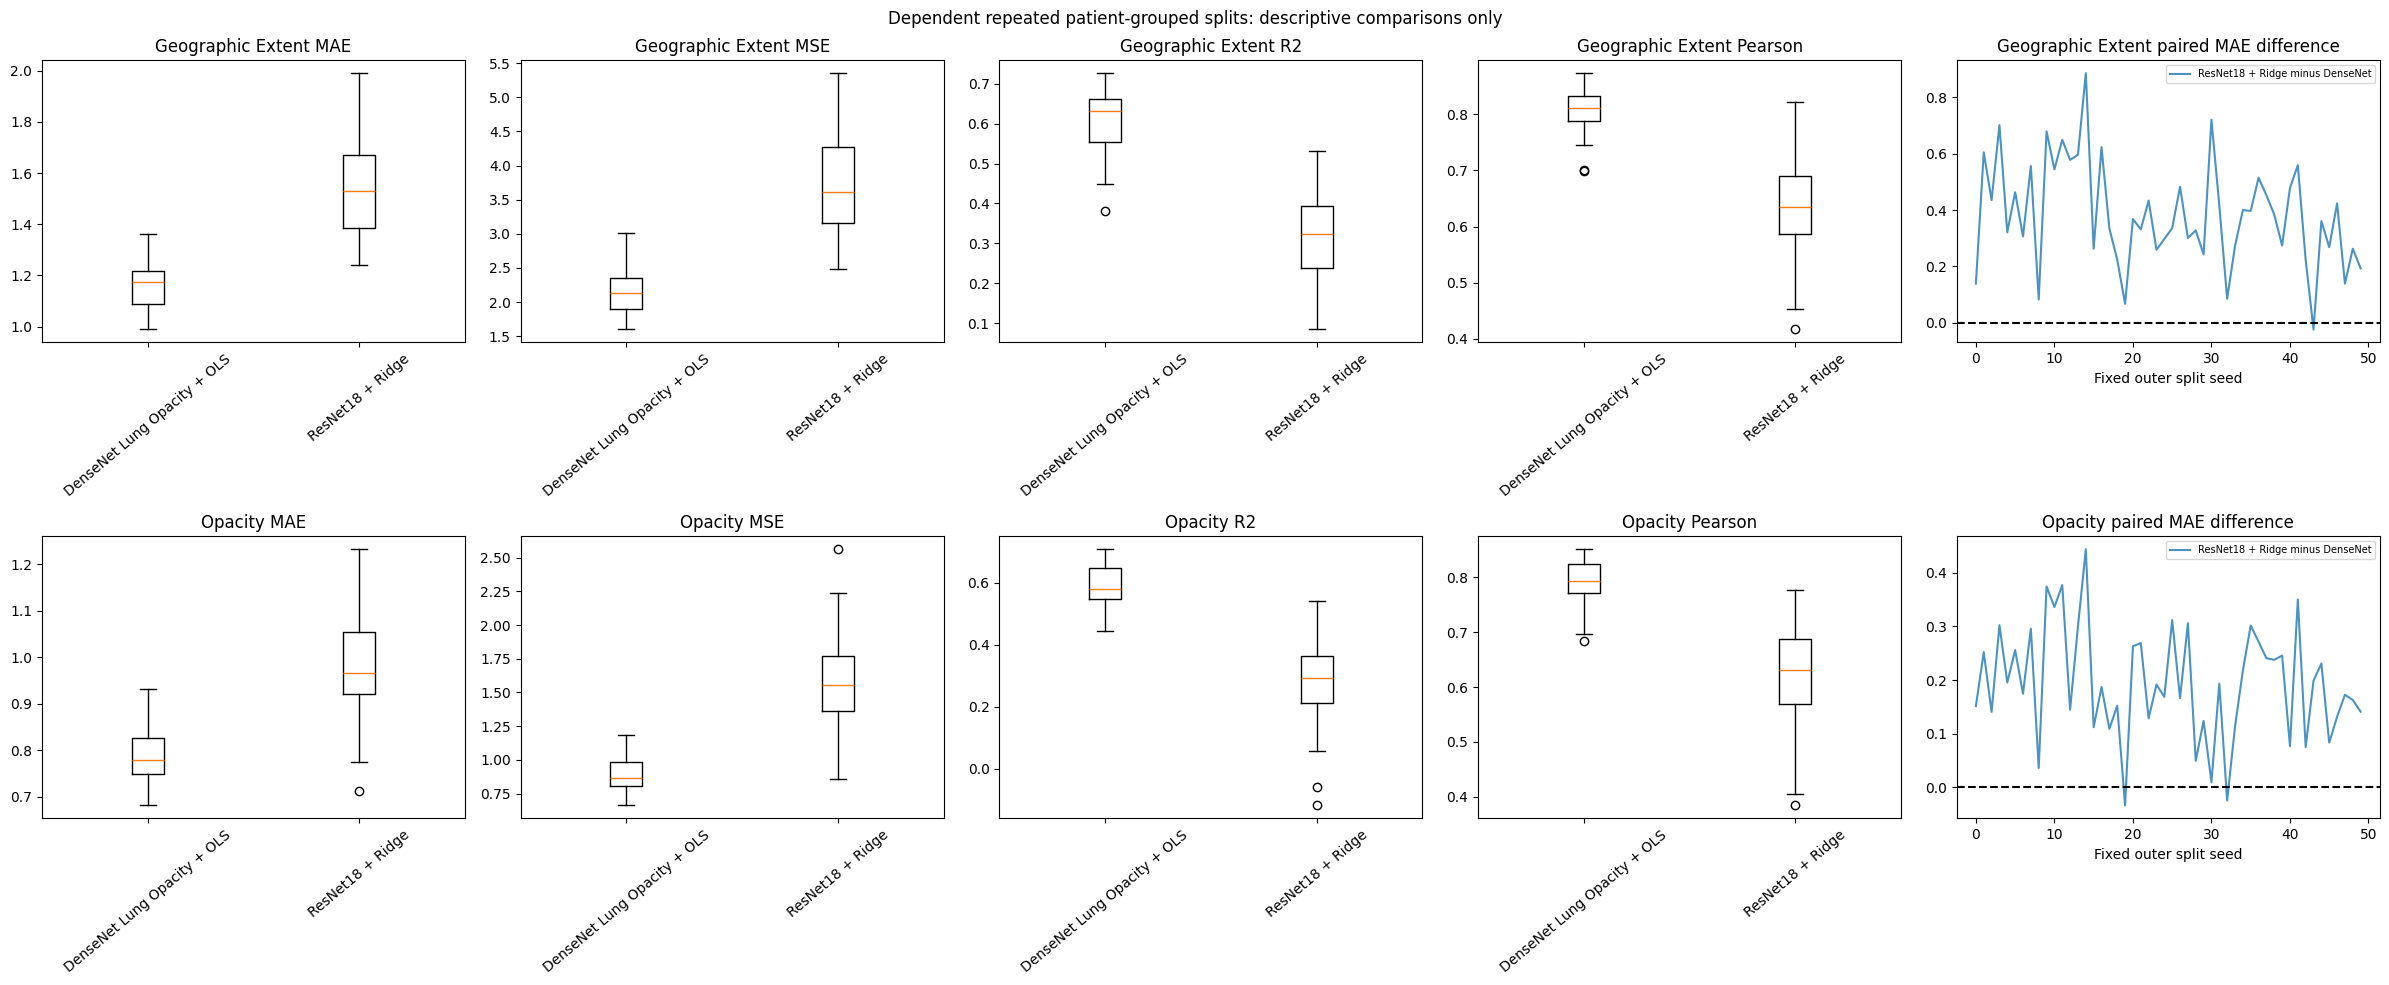

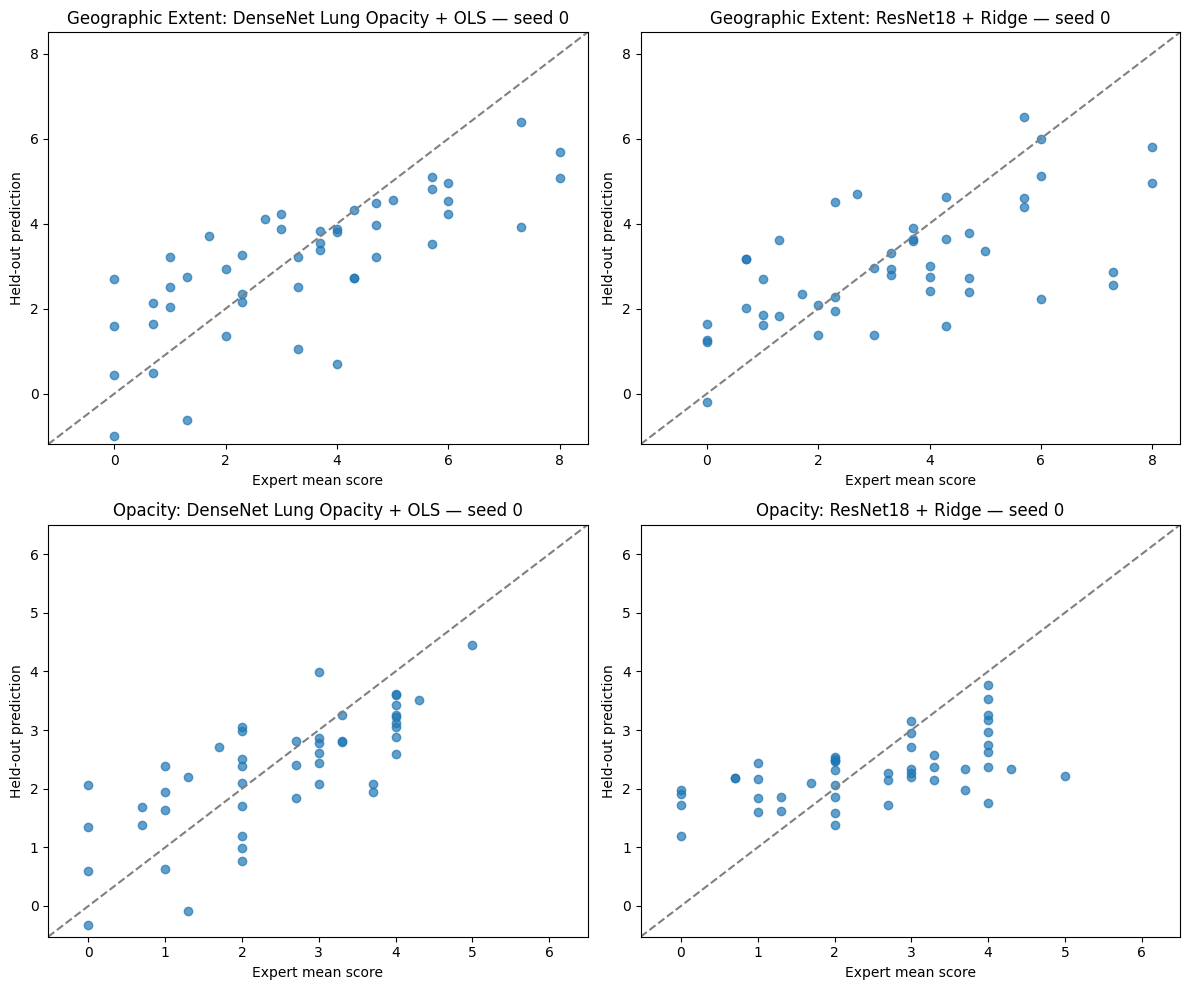

In [19]:
import matplotlib.pyplot as plt
models=[BASELINE,RIDGE]+([PCA_RIDGE] if INCLUDE_PCA else [])
fig,axes=plt.subplots(2,5,figsize=(24,10))
for i,target in enumerate(['Geographic Extent','Opacity']):
    part=by_seed[by_seed.target==target]
    for j,metric in enumerate(['MAE','MSE','R2','Pearson']):
        values=[part[part.model==m][metric].dropna().to_numpy() for m in models]
        axes[i,j].boxplot(values,labels=models)
        axes[i,j].tick_params(axis='x',rotation=40);axes[i,j].set_title(target+' '+metric)
    differences=paired.loc[target]
    for name in diff_columns:
        axes[i,4].plot(differences.index,differences[name],label=name,alpha=.8)
    axes[i,4].axhline(0,color='black',linestyle='--');axes[i,4].set_title(target+' paired MAE difference')
    axes[i,4].set_xlabel('Fixed outer split seed');axes[i,4].legend(fontsize=7)
fig.suptitle('Dependent repeated patient-grouped splits: descriptive comparisons only')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'paired_model_comparison.png',dpi=180);plt.show()
fig,axes=plt.subplots(2,len(models),figsize=(6*len(models),10))
for i,(target,max_score) in enumerate([('Geographic Extent',8),('Opacity',6)]):
    common=predictions[(predictions.target==target)&(predictions.seed==SCATTER_SEED)]
    lo=min(-.5,float(common.y_pred.min())-.2);hi=max(max_score+.5,float(common.y_pred.max())+.2)
    for j,model in enumerate(models):
        p=common[common.model==model]
        axes[i,j].scatter(p.y_true,p.y_pred,alpha=.7)
        axes[i,j].plot([lo,hi],[lo,hi],'--',color='gray')
        axes[i,j].set(xlim=(lo,hi),ylim=(lo,hi),xlabel='Expert mean score',ylabel='Held-out prediction',
            title=f'{target}: {model} — seed {SCATTER_SEED}')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'resnet18_prediction_scatter.png',dpi=180);plt.show()


## Interpretation and limitations
Use the exported paired differences to describe whether the **observed** ResNet pipeline performs better or worse on these fixed splits. Do not call the 50 overlapping splits independent experiments, convert their SD into an independent-replication SE, or report an uncorrected paired t-test as proof of superiority. The seed-0 scatter is prespecified and is not a representative sample of all possible patient splits.

Only 65 patients underlie 94 expert-scored images. Label averaging and inter-rater disagreement limit precision; ordinal-derived scores are treated as continuous to match the original analysis. External hospitals and prospective clinical utility remain untested. ImageNet features may encode different acquisition cues than CXR-pretrained DenseNet; differences cannot be attributed solely to architecture. Unknown historical pretraining/cohort provenance remains a limitation even with newly recorded hashes. No causal/clinical conclusions follow from predictive accuracy alone.

**Execution status:** this notebook contains no saved experimental numbers or figures. It becomes a real-data comparison only after all data, feature, split and provenance checks pass. If historical records are absent, regenerated split consistency is verified but exact alignment with the unavailable prior run remains unverified. A count of 94/65 alone cannot prove the historical cohort is identical. GPU absence does not prevent the CPU experiment; missing data does.
